# 03 — Kinetics

Measured force-platform QC - Inspect Vicon force plate data before attempting SAM kinetic estimation. Unverified force directions or CoP are not physical validation results.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir(): ROOT = ROOT.parent
if not (ROOT / 'src').is_dir(): raise FileNotFoundError('Cannot find project root')
sys.path.insert(0,str(ROOT))
SUBJECT = 'S1'
TRIAL = 'lunge_01'
C3D_PATH = ROOT/'lunge_sam_out'/SUBJECT/TRIAL/f'{SUBJECT.lower()}_lunge_0_1.c3d'
OUT = ROOT/'results'/SUBJECT/TRIAL/'kinetics_qc'
if not C3D_PATH.is_file(): raise FileNotFoundError(C3D_PATH)
OUT.mkdir(parents=True,exist_ok=True)
print(C3D_PATH)


/Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S1/lunge_01/s1_lunge_0_1.c3d


## Inspect C3D and force-platform metadata

Check force/CoP units, channel mapping, plate origins, plate frame axes and point/analog timebase.


In [2]:
import ezc3d
c3d=ezc3d.c3d(str(C3D_PATH), extract_forceplat_data=True)
analog_rate=float(c3d['header']['analogs']['frame_rate'])
print('Marker Hz:',c3d['header']['points']['frame_rate'],'Analog Hz:',analog_rate)
print('Analog shape:',c3d['data']['analogs'].shape)
for group in ['ANALOG','FORCE_PLATFORM']:
    print('\n',group)
    for k, v in c3d['parameters'].get(group,{}).items():
        if k in ('USED','RATE','LABELS','UNITS','TYPE','CHANNEL','ORIGIN','CORNERS','ZERO','CAL_MATRIX'):
            print(k, str(v.get('value'))[:1500])
platforms=c3d['data'].get('platform',[])
print('Extracted platforms:',len(platforms))
for i,plate in enumerate(platforms):
    print('Plate',i+1,[(k,np.shape(v)) for k,v in plate.items()])


Marker Hz: 100.0 Analog Hz: 1000.0
Analog shape: (1, 60, 9750)

 ANALOG
RATE [1000.]
USED [60]
UNITS ['N', 'N', 'N', 'Nmm', 'Nmm', 'Nmm', 'N', 'N', 'N', 'Nmm', 'Nmm', 'Nmm', 'N', 'N', 'N', 'Nmm', 'Nmm', 'Nmm', 'N', 'N', 'N', 'Nmm', 'Nmm', 'Nmm', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V']
LABELS ['Force.Fx1', 'Force.Fy1', 'Force.Fz1', 'Moment.Mx1', 'Moment.My1', 'Moment.Mz1', 'Force.Fx2', 'Force.Fy2', 'Force.Fz2', 'Moment.Mx2', 'Moment.My2', 'Moment.Mz2', 'Force.Fx3', 'Force.Fy3', 'Force.Fz3', 'Moment.Mx3', 'Moment.My3', 'Moment.Mz3', 'Force.Fx4', 'Force.Fy4', 'Force.Fz4', 'Moment.Mx4', 'Moment.My4', 'Moment.Mz4', 'Raw.Pin 9', 'Raw.Pin 10', 'Raw.Pin 11', 'Raw.Pin 12', 'Raw.Pin 13', 'Raw.Pin 14', 'Voltage.EMG_A01', 'Voltage.EMG_A02', 'Voltage.EMG_A03', 'Voltage.EMG_A04', 'Voltage.EMG_A05', 'Voltage.EMG_A06', 'Voltage.EMG_A07', 'Voltage.EMG_A08', 'Voltag

## Plot measured force components

Components are *not* identified as vertical GRF until the lab axes and calibration are verified.


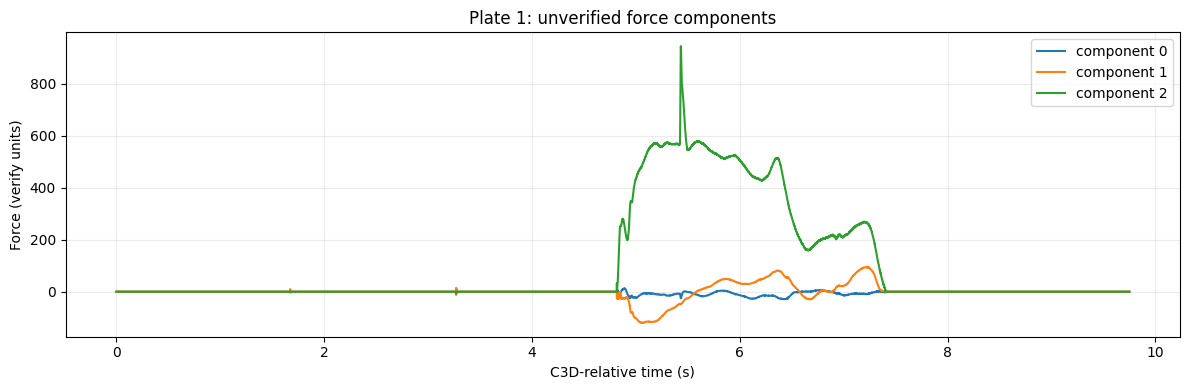

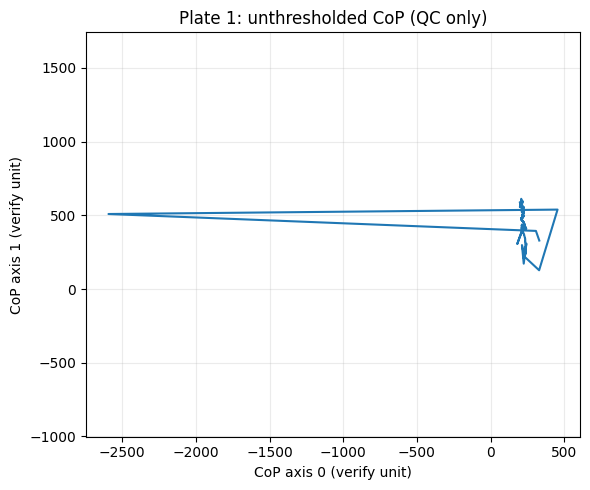

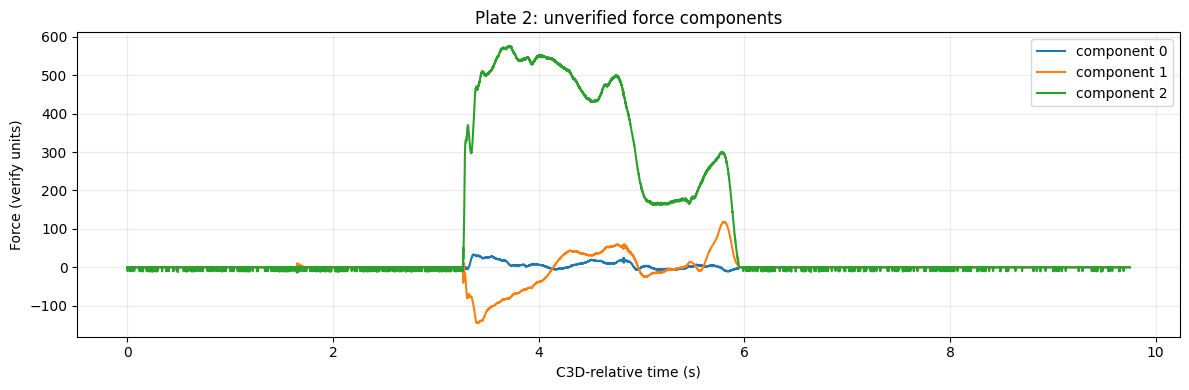

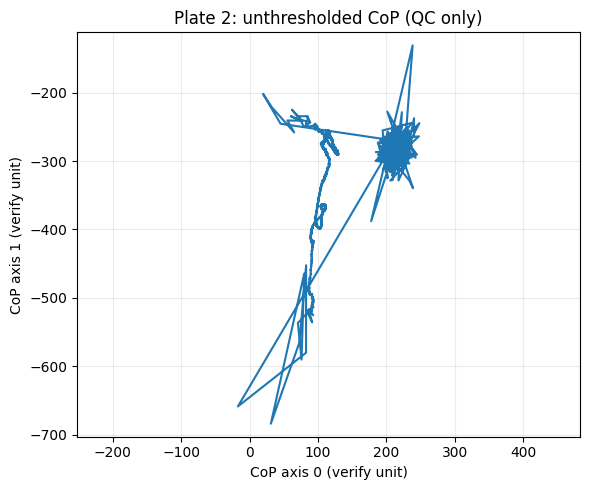

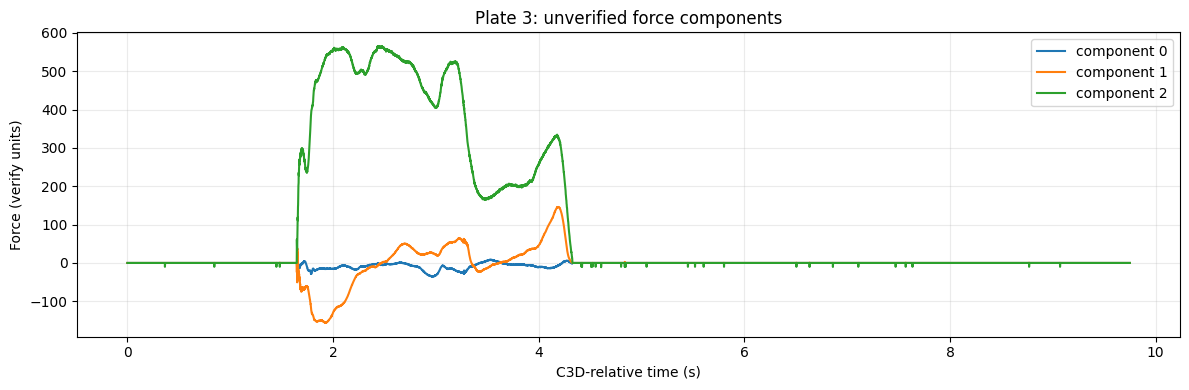

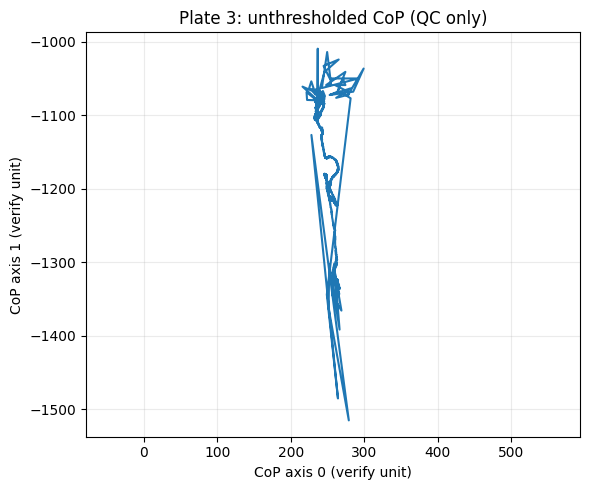

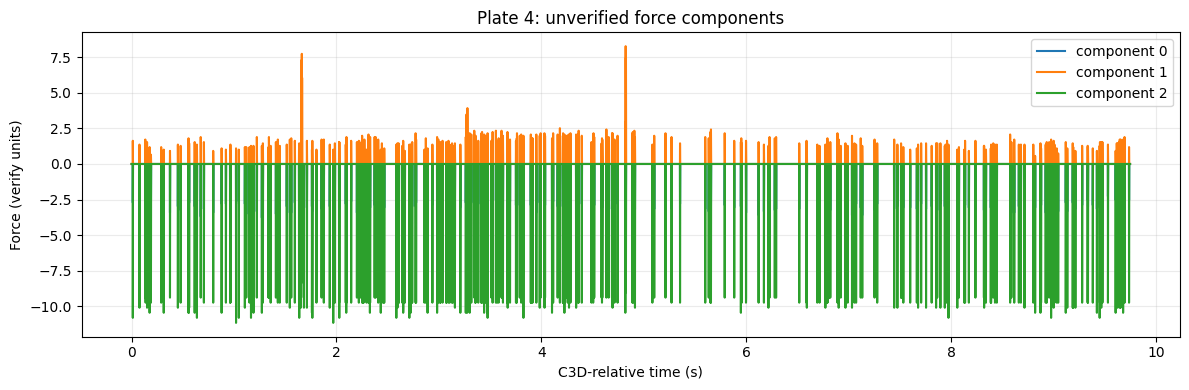

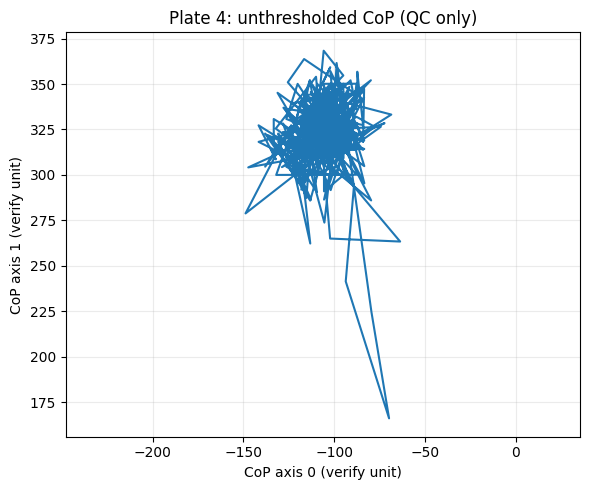

In [3]:
def three_by_n(a):
    a=np.squeeze(np.asarray(a,dtype=float))
    if a.ndim!=2: raise ValueError(f'Unexpected array shape {a.shape}')
    if a.shape[0]==3: return a
    if a.shape[1]==3: return a.T
    raise ValueError(f'No three-axis dimension: {a.shape}')

qc=[]
for i,plate in enumerate(platforms,1):
    f=three_by_n(plate['force'])
    t=np.arange(f.shape[1])/analog_rate
    fig,ax=plt.subplots(figsize=(12,4))
    for j in range(3): ax.plot(t,f[j],label=f'component {j}')
    ax.set(xlabel='C3D-relative time (s)',ylabel='Force (verify units)',title=f'Plate {i}: unverified force components')
    ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(OUT/f'plate_{i}_force_components.png',dpi=160);plt.show()
    qc.append(dict(plate=i,n_samples=f.shape[1],duration_s=t[-1]))
    if 'center_of_pressure' in plate:
        cop=three_by_n(plate['center_of_pressure'])
        valid=np.isfinite(cop[:2]).all(axis=0)
        if valid.any():
            fig,ax=plt.subplots(figsize=(6,5));ax.plot(cop[0,valid],cop[1,valid]);ax.axis('equal')
            ax.set(xlabel='CoP axis 0 (verify unit)',ylabel='CoP axis 1 (verify unit)',title=f'Plate {i}: unthresholded CoP (QC only)')
            ax.grid(alpha=.25);fig.tight_layout();fig.savefig(OUT/f'plate_{i}_cop_raw.png',dpi=160);plt.show()
if not platforms: print('No extracted calibrated platforms: inspect metadata and analog channel mapping before proceeding')
pd.DataFrame(qc).to_csv(OUT/'platform_qc.csv',index=False)


Plate 1: force unit = N position unit = mm
Plate 2: force unit = N position unit = mm
Plate 3: force unit = N position unit = mm
Plate 4: force unit = N position unit = mm
Plate 1: peak=944.6 N, contact samples=2571
Plate 2: peak=575.8 N, contact samples=2671
Plate 3: peak=565.6 N, contact samples=2674
Plate 4: peak=0.0 N, contact samples=0


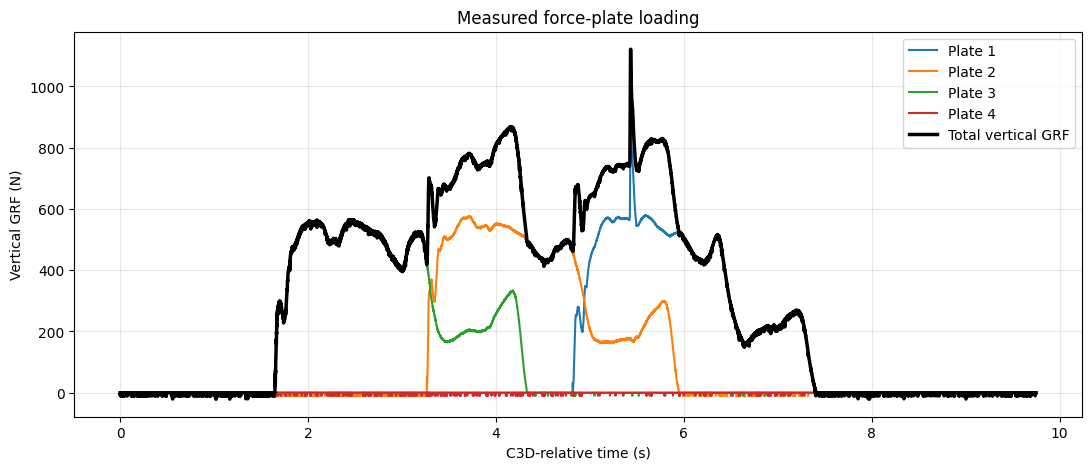

In [4]:
# Provisional threshold; refine after checking noise and units.
CONTACT_THRESHOLD_N = 20.0

# Only proceed after verifying the units and orientation.
for i, plate in enumerate(platforms):
    print(
        f"Plate {i+1}:",
        "force unit =", plate.get("unit_force"),
        "position unit =", plate.get("unit_position"),
    )

vertical_axis = 2
analog_rate = float(c3d["header"]["analogs"]["frame_rate"])

fig, ax = plt.subplots(figsize=(13, 5))

total_fz = None

for i, plate in enumerate(platforms):
    force = np.asarray(plate["force"], dtype=float)
    fz = force[vertical_axis, :]

    t = np.arange(len(fz)) / analog_rate

    if total_fz is None:
        total_fz = np.zeros_like(fz)
    else:
        assert len(total_fz) == len(fz), "Mismatched force sampling"

    total_fz += fz

    contact = fz > CONTACT_THRESHOLD_N
    print(
        f"Plate {i+1}: "
        f"peak={fz.max():.1f} N, "
        f"contact samples={contact.sum()}"
    )

    ax.plot(t, fz, label=f"Plate {i+1}")

ax.plot(
    t, total_fz,
    color="black",
    linewidth=2.5,
    label="Total vertical GRF"
)

ax.set(
    xlabel="C3D-relative time (s)",
    ylabel="Vertical GRF (N)",
    title="Measured force-plate loading"
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

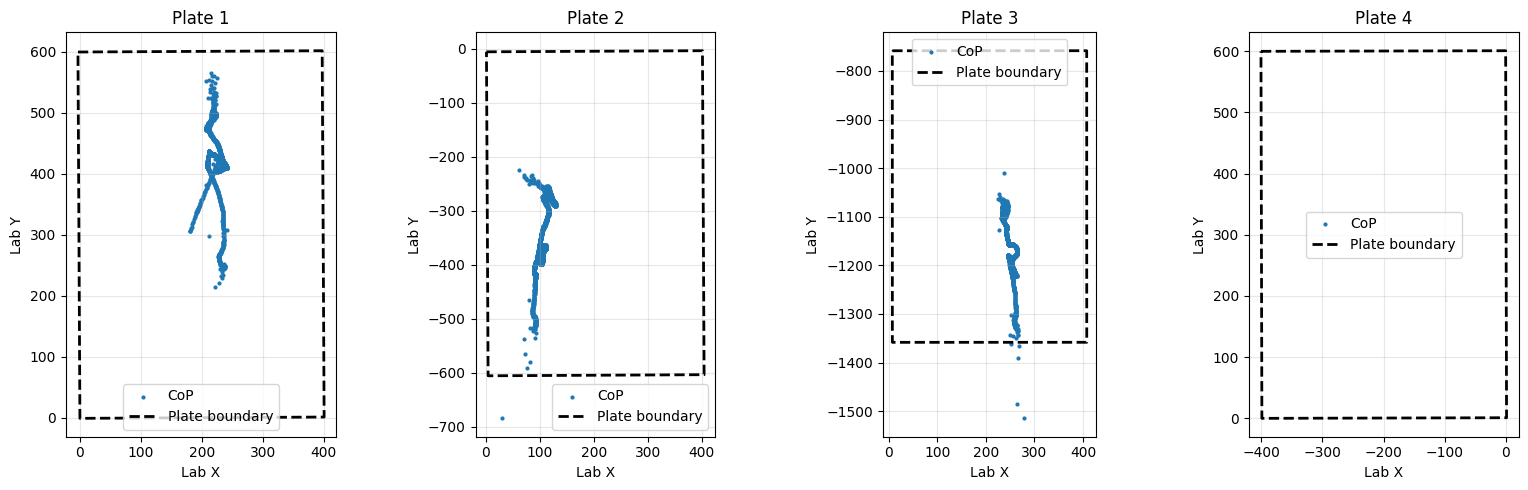

In [7]:

fig, axes = plt.subplots(
    1, len(platforms),
    figsize=(4 * len(platforms), 5),
    squeeze=False
)

for i, plate in enumerate(platforms):
    ax = axes[0, i]

    force = np.asarray(plate["force"], dtype=float)
    cop = np.asarray(plate["center_of_pressure"], dtype=float)
    corners = np.asarray(plate["corners"], dtype=float)

    contact = (
        (force[2] > CONTACT_THRESHOLD_N)
        & np.isfinite(cop[0])
        & np.isfinite(cop[1])
    )

    # CoP during loaded periods
    ax.scatter(
        cop[0, contact],
        cop[1, contact],
        s=4,
        label="CoP"
    )

    # Force-platform outline
    xy = corners[:2, :]
    outline = np.column_stack([xy, xy[:, 0]])

    ax.plot(
        outline[0],
        outline[1],
        "k--",
        linewidth=2,
        label="Plate boundary"
    )

    ax.set_title(f"Plate {i+1}")
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Lab X")
    ax.set_ylabel("Lab Y")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [8]:

for i, plate in enumerate(platforms):
    force = np.asarray(plate["force"], dtype=float)
    cop = np.asarray(plate["center_of_pressure"], dtype=float)
    corners = np.asarray(plate["corners"], dtype=float)

    contact = (
        (force[2] > CONTACT_THRESHOLD_N)
        & np.isfinite(cop[0])
        & np.isfinite(cop[1])
    )

    if not contact.any():
        print(f"Plate {i+1}: no loaded samples")
        continue

    xy = corners[:2, :]

    inside = (
        (cop[0] >= xy[0].min())
        & (cop[0] <= xy[0].max())
        & (cop[1] >= xy[1].min())
        & (cop[1] <= xy[1].max())
    )

    percentage_inside = 100 * np.mean(inside[contact])

    print(
        f"Plate {i+1}: "
        f"{percentage_inside:.1f}% of loaded CoP samples inside boundaries"
    )

Plate 1: 100.0% of loaded CoP samples inside boundaries
Plate 2: 100.0% of loaded CoP samples inside boundaries
Plate 3: 99.8% of loaded CoP samples inside boundaries
Plate 4: no loaded samples


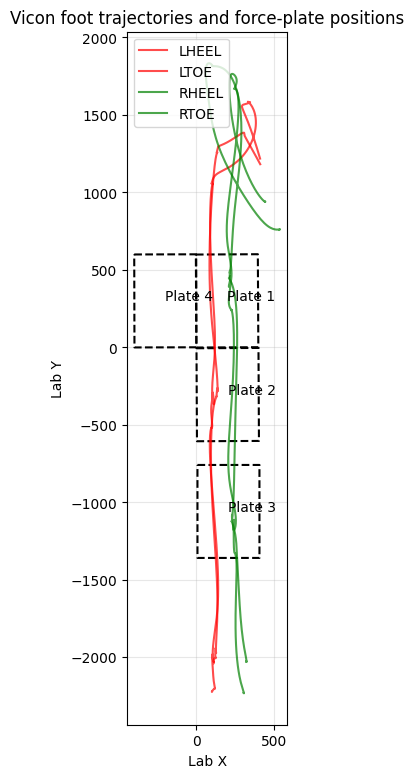

In [9]:
labels = list(c3d["parameters"]["POINT"]["LABELS"]["value"])
points = np.asarray(c3d["data"]["points"])

def marker_xy(name):
    idx = labels.index(name)
    coords = points[:3, idx, :].T.astype(float)
    return coords[:, :2]

fig, ax = plt.subplots(figsize=(9, 9))

for i, plate in enumerate(platforms):
    corners = np.asarray(plate["corners"], dtype=float)

    xy = corners[:2, :]
    outline = np.column_stack([xy, xy[:, 0]])

    ax.plot(
        outline[0],
        outline[1],
        "k--",
        linewidth=1.5
    )

    center = xy.mean(axis=1)
    ax.text(center[0], center[1], f"Plate {i+1}")

for marker, color in [
    ("LHEEL", "red"),
    ("LTOE", "red"),
    ("RHEEL", "green"),
    ("RTOE", "green")
]:
    xy = marker_xy(marker)

    ax.plot(
        xy[:, 0],
        xy[:, 1],
        color=color,
        label=marker,
        alpha=0.7
    )

ax.set_aspect("equal")
ax.set_xlabel("Lab X")
ax.set_ylabel("Lab Y")
ax.set_title("Vicon foot trajectories and force-plate positions")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

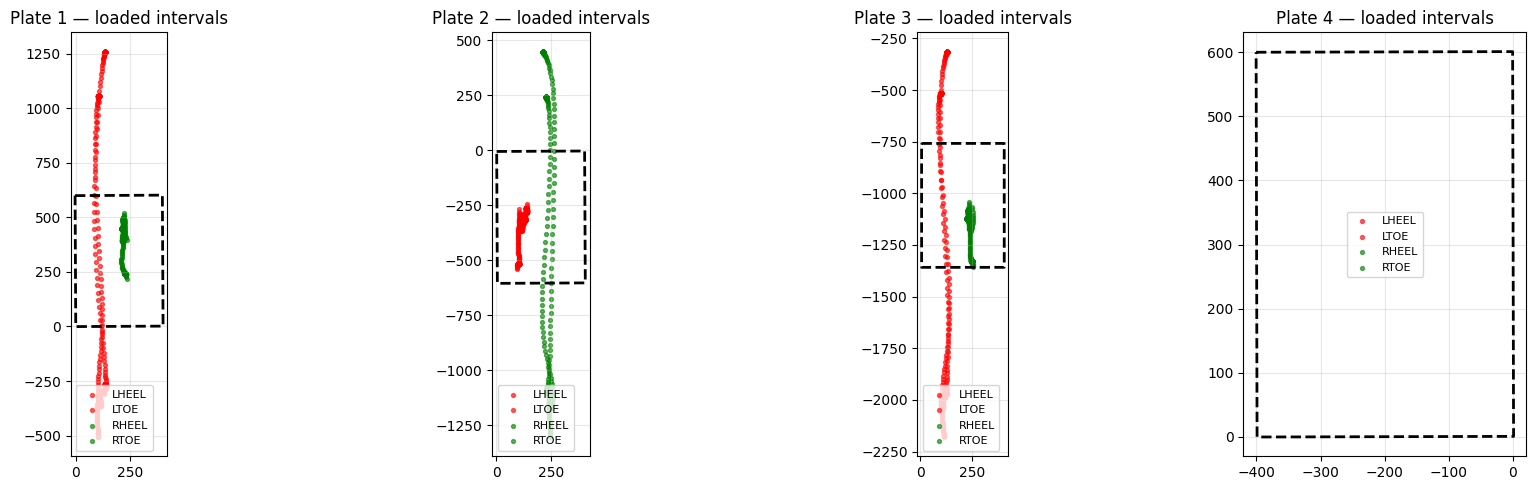

,plate,start_s,end_s,duration_s,peak_fz_N
0,3,1.648,4.322,2.674,565.624342
1,2,3.267,5.936,2.669,575.801213
2,1,4.821,7.390,2.569,944.629120


In [11]:
# Plot foot markers during loaded periods, relative to the same recording origin.
point_rate = float(c3d["header"]["points"]["frame_rate"])
analog_rate = float(c3d["header"]["analogs"]["frame_rate"])

labels = list(c3d["parameters"]["POINT"]["LABELS"]["value"])
points = np.asarray(c3d["data"]["points"])

def get_marker_xy(name):
    idx = labels.index(name)
    xyz = points[:3, idx, :].T.astype(float)

    # Invalid markers are excluded.
    residual = points[3, idx, :]
    xyz[residual < 0] = np.nan

    return xyz[:, :2]

marker_names = ["LHEEL", "LTOE", "RHEEL", "RTOE"]
markers = {name: get_marker_xy(name) for name in marker_names}

fig, axes = plt.subplots(
    1, len(platforms),
    figsize=(18, 5),
    squeeze=False
)

for i, plate in enumerate(platforms):
    ax = axes[0, i]

    force = np.asarray(plate["force"], dtype=float)
    corners = np.asarray(plate["corners"], dtype=float)

    fz = force[2]
    force_t = np.arange(len(fz)) / analog_rate

    # Marker-frame time, relative to the same recording origin.
    marker_t = np.arange(points.shape[2]) / point_rate

    # Identify marker frames occurring during plate loading.
    force_at_marker = np.interp(marker_t, force_t, fz)
    contact = force_at_marker > CONTACT_THRESHOLD_N

    xy = corners[:2, :]
    outline = np.column_stack([xy, xy[:, 0]])

    ax.plot(outline[0], outline[1], "k--", linewidth=2)

    for name, color in [
        ("LHEEL", "red"),
        ("LTOE", "red"),
        ("RHEEL", "green"),
        ("RTOE", "green"),
    ]:
        positions = markers[name]
        ax.scatter(
            positions[contact, 0],
            positions[contact, 1],
            s=8,
            color=color,
            alpha=0.6,
            label=name
        )

    ax.set_title(f"Plate {i+1} — loaded intervals")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Identify contact events and their durations.
MIN_CONTACT_DURATION_S = 0.10

analog_rate = float(c3d["header"]["analogs"]["frame_rate"])

events = []

for plate_idx, plate in enumerate(platforms):
    fz = np.asarray(plate["force"], dtype=float)[2]

    contact = fz > CONTACT_THRESHOLD_N

    # Find transitions into and out of contact
    changes = np.diff(
        np.r_[False, contact, False].astype(int)
    )

    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    for start, end in zip(starts, ends):
        duration = (end - start) / analog_rate

        if duration < MIN_CONTACT_DURATION_S:
            continue

        events.append({
            "plate": plate_idx + 1,
            "start_s": start / analog_rate,
            "end_s": end / analog_rate,
            "duration_s": duration,
            "peak_fz_N": np.max(fz[start:end]),
        })

events_df = pd.DataFrame(events)

if not events_df.empty:
    events_df = events_df.sort_values("start_s").reset_index(drop=True)

display(events_df)

In [12]:
point_rate = float(c3d["header"]["points"]["frame_rate"])
marker_t = np.arange(points.shape[2]) / point_rate

rows = []

for event in events_df.itertuples(index=False):
    plate_idx = int(event.plate) - 1
    plate = platforms[plate_idx]

    start, end = event.start_s, event.end_s
    mask = (marker_t >= start) & (marker_t < end)

    corners = np.asarray(plate["corners"], dtype=float)
    xmin, xmax = corners[0].min(), corners[0].max()
    ymin, ymax = corners[1].min(), corners[1].max()

    for side in ("L", "R"):
        heel = markers[f"{side}HEEL"]
        toe = markers[f"{side}TOE"]

        foot_center = 0.5 * (heel + toe)
        xy = foot_center[mask]

        finite = np.isfinite(xy).all(axis=1)

        inside = (
            finite
            & (xy[:, 0] >= xmin)
            & (xy[:, 0] <= xmax)
            & (xy[:, 1] >= ymin)
            & (xy[:, 1] <= ymax)
        )

        rows.append({
            "plate": event.plate,
            "side": side,
            "fraction_inside": (
                inside.sum() / finite.sum()
                if finite.sum() else np.nan
            ),
            "median_x": np.nanmedian(xy[:, 0]),
            "median_y": np.nanmedian(xy[:, 1]),
        })

assignment_qc = pd.DataFrame(rows)
display(assignment_qc)

,plate,side,fraction_inside,median_x,median_y
0,3,L,0.059701,115.685974,-1282.335602
1,3,R,1.000000,239.490582,-1223.794159
2,2,L,1.000000,115.862106,-414.866043
3,2,R,0.063670,234.228523,-285.575966
4,1,L,0.070312,120.131697,89.786438
5,1,R,1.000000,218.667366,344.926155


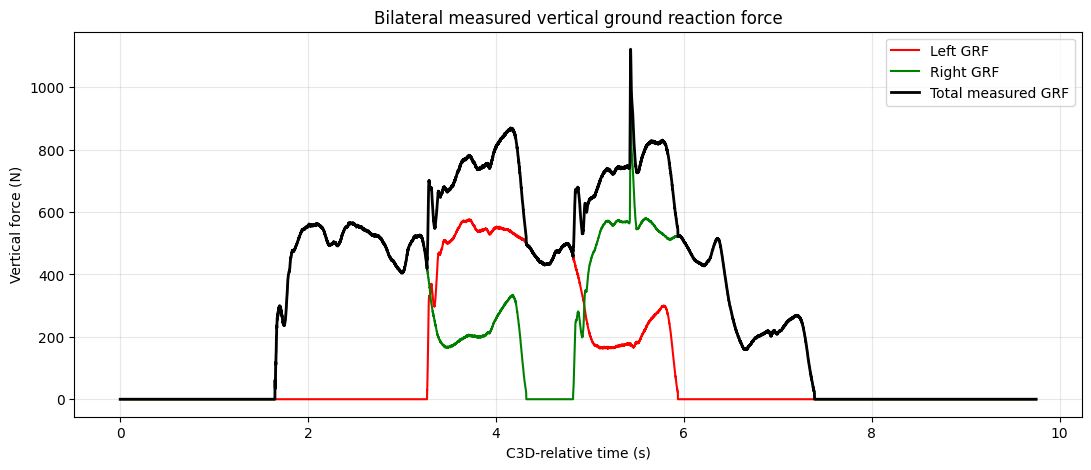

In [13]:

# Event-specific assignments from spatial QC
contact_assignments = {
    3: "R",
    2: "L",
    1: "R",
}

analog_rate = float(c3d["header"]["analogs"]["frame_rate"])

n_samples = len(np.asarray(platforms[0]["force"])[2])
time_s = np.arange(n_samples) / analog_rate

left_fz = np.zeros(n_samples)
right_fz = np.zeros(n_samples)

for event in events_df.itertuples(index=False):
    plate_number = int(event.plate)
    side = contact_assignments[plate_number]

    plate = platforms[plate_number - 1]
    force = np.asarray(plate["force"], dtype=float)
    fz = force[2]

    start_idx = max(0, int(round(event.start_s * analog_rate)))
    end_idx = min(n_samples, int(round(event.end_s * analog_rate)))

    if side == "L":
        left_fz[start_idx:end_idx] += fz[start_idx:end_idx]
    else:
        right_fz[start_idx:end_idx] += fz[start_idx:end_idx]

total_fz = left_fz + right_fz

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(time_s, left_fz, color="red", label="Left GRF")
ax.plot(time_s, right_fz, color="green", label="Right GRF")
ax.plot(time_s, total_fz, color="black", linewidth=2, label="Total measured GRF")

ax.set(
    xlabel="C3D-relative time (s)",
    ylabel="Vertical force (N)",
    title="Bilateral measured vertical ground reaction force"
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [15]:
KINETICS_DIR = ROOT / "results" / SUBJECT / TRIAL / "kinetics"
KINETICS_DIR.mkdir(parents=True, exist_ok=True)

assignments_df = events_df.copy()
assignments_df["side"] = assignments_df["plate"].map(contact_assignments)
assignments_df["assignment_method"] = "vicon_foot_center_inside_plate"

assignments_df.to_csv(
    KINETICS_DIR / "foot_plate_assignments.csv",
    index=False
)

np.savez_compressed(
    KINETICS_DIR / "bilateral_grf_reference.npz",
    time_s=time_s,
    left_fz_N=left_fz,
    right_fz_N=right_fz,
    total_fz_N=total_fz,
)

print("Saved kinetic reference to:", KINETICS_DIR)

Saved kinetic reference to: /Users/thomasjohnson/markerless/markerless_sam/results/S1/lunge_01/kinetics


## Physics informed kinetics estimation

## Scientific gates

- Verify calibrated plate forces, vertical sign and units against lab configuration; define contact threshold and exclude CoP outside contact.
- Confirm analog/marker clock origin within C3D; align SAM video-derived timestamps to this clock using the **camera-specific reviewed** synchronization. Never shift Vicon data twice.
- Determine which foot contacts which plate and obtain body mass/height.
- Verify SAM root trajectory, absolute scale, coordinate frame, full-body markers/mesh and actual video timestamps before differentiating COM twice.
- Proceed to measured GRF and CoP, then estimated total GRF, and only then bilateral inverse dynamics with contact and inertial assumptions.
